# 06 - Random Forest tuning, U.S. training only

This notebook tunes Random Forest using the official U.S. training rows and the same conservative feature policy used by the other model-specific notebooks. It compares validation performance with model complexity and fit time.


In [1]:
from pathlib import Path
import sys, warnings
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'utils' / 'preprocessing.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import randint
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
from utils.us_modeling import (CONSERVATIVE_POLICY, development_cv, load_us_training_data,
    run_randomized_search, scoring, search_result, conservative_pipeline)
SEED = 42
X_train, y_train, project_ids = load_us_training_data(ROOT)
assert len(project_ids) == 26945 and project_ids.is_unique
assert np.isfinite(y_train).all() and set(y_train.unique()) == {0, 1}
assert CONSERVATIVE_POLICY == dict(include_timing=False, include_flags=False, include_reward=False, exclude_renamed=True)
baseline = conservative_pipeline(RandomForestClassifier(n_estimators=250, min_samples_leaf=5, n_jobs=1, random_state=SEED), 'target')
base_scores = cross_validate(baseline, X_train, y_train, cv=development_cv(), scoring=scoring(), n_jobs=1, return_train_score=True, error_score='raise')
baseline_row = {m: float(base_scores[f'test_{m}'].mean()) for m in scoring()}
baseline_row['roc_auc_sd'] = float(base_scores['test_roc_auc'].std())
print(f'official U.S. training rows: {len(X_train):,}; success rate: {y_train.mean():.4f}')
print('baseline:', {k: round(v, 4) for k, v in baseline_row.items()})


official U.S. training rows: 26,945; success rate: 0.5461
baseline: {'roc_auc': 0.7116, 'accuracy': 0.6585, 'f1': 0.7037, 'roc_auc_sd': 0.0065}


In [2]:
model = RandomForestClassifier(n_jobs=1, random_state=SEED)
space = {
    'model__n_estimators': randint(150, 601),
    'model__max_depth': [None, 10, 16, 24],
    'model__min_samples_leaf': randint(2, 21),
    'model__min_samples_split': randint(2, 12),
    'model__max_features': ['sqrt', 0.5, 1.0],
    'model__class_weight': [None, 'balanced'],
}
search, trials = run_randomized_search(X_train, y_train, model, 'target', space, n_iter=15)
result = search_result(search, trials, 'Random Forest')
result['baseline_roc_auc'] = baseline_row['roc_auc']
display(pd.DataFrame([result]).drop(columns=['best_params']).round(4))
print('best parameters:', result['best_params'])
display(trials.head(10).drop(columns=['params']).round(4))


,model,cohort,feature_policy,cv,search_iterations,estimate,cv_roc_auc,cv_roc_auc_sd,train_roc_auc,overfit_gap,accuracy,f1,fit_seconds,elapsed_seconds,baseline_roc_auc
0,Random Forest,official U.S. training rows,"conservative: no timing, flags, rewards, or re...",5-fold StratifiedKFold shuffle=True random_sta...,15,ordinary tuning CV; optimistic selection estimate,0.7216,0.0066,0.7681,0.0464,0.6641,0.6946,3.4907,1185.4215,0.7116


best parameters: {'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 19, 'min_samples_split': 11, 'n_estimators': 193}


,trial_rank,cv_roc_auc,cv_roc_auc_sd,train_roc_auc,cv_accuracy,cv_f1,mean_fit_seconds,overfit_gap,elapsed_seconds
0,1,0.7216,0.0066,0.7681,0.6641,0.6946,3.4907,0.0464,1185.4215
1,2,0.7212,0.0062,0.7884,0.6665,0.7144,9.9931,0.0672,1185.4215
2,3,0.7208,0.0067,0.7953,0.6632,0.6961,11.7294,0.0744,1185.4215
3,4,0.7208,0.0056,0.7890,0.6654,0.6972,3.0362,0.0682,1185.4215
4,5,0.7206,0.0068,0.7915,0.6642,0.7102,6.6723,0.0710,1185.4215
5,6,0.7201,0.0068,0.7974,0.6646,0.7106,6.6857,0.0773,1185.4215
6,7,0.7197,0.0067,0.7945,0.6644,0.7103,16.1676,0.0748,1185.4215
7,8,0.7192,0.0071,0.7980,0.6653,0.7111,14.4173,0.0788,1185.4215
8,9,0.7187,0.0066,0.8054,0.6616,0.6921,18.0088,0.0868,1185.4215
9,10,0.7182,0.0069,0.8075,0.6617,0.6914,20.9874,0.0893,1185.4215


baseline AUC 0.7116; tuned AUC 0.7216; difference +0.0100
The chosen forest should balance score, gap, and fit time. A larger tree count is not automatically preferable.


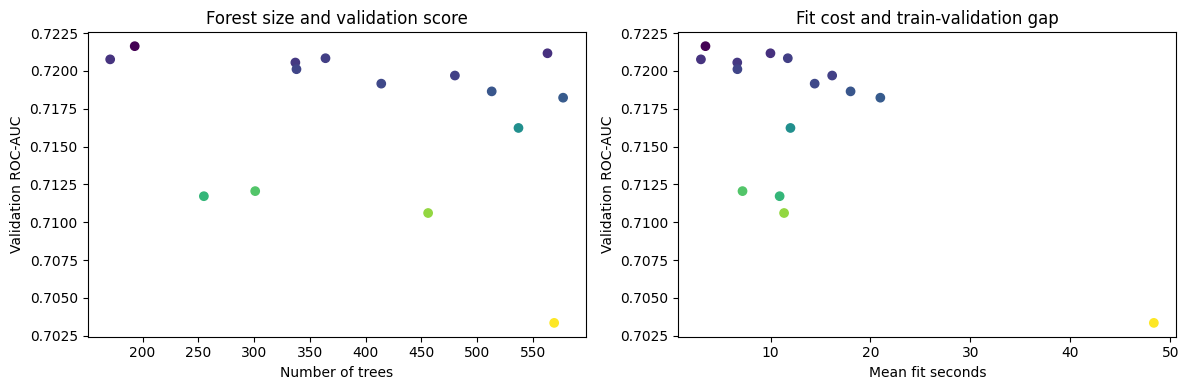

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(trials['params'].map(lambda p: p.get('model__n_estimators')), trials['cv_roc_auc'], c=trials['overfit_gap'], cmap='viridis')
axes[0].set_xlabel('Number of trees'); axes[0].set_ylabel('Validation ROC-AUC'); axes[0].set_title('Forest size and validation score')
axes[1].scatter(trials['mean_fit_seconds'], trials['cv_roc_auc'], c=trials['overfit_gap'], cmap='viridis')
axes[1].set_xlabel('Mean fit seconds'); axes[1].set_ylabel('Validation ROC-AUC'); axes[1].set_title('Fit cost and train-validation gap')
plt.tight_layout()
print(f"baseline AUC {baseline_row['roc_auc']:.4f}; tuned AUC {result['cv_roc_auc']:.4f}; difference {result['cv_roc_auc'] - baseline_row['roc_auc']:+.4f}")
print('The chosen forest should balance score, gap, and fit time. A larger tree count is not automatically preferable.')


The baseline is the previously verified U.S. Random Forest configuration. The search uses 15 reproducible trials to keep this preliminary comparison practical.
